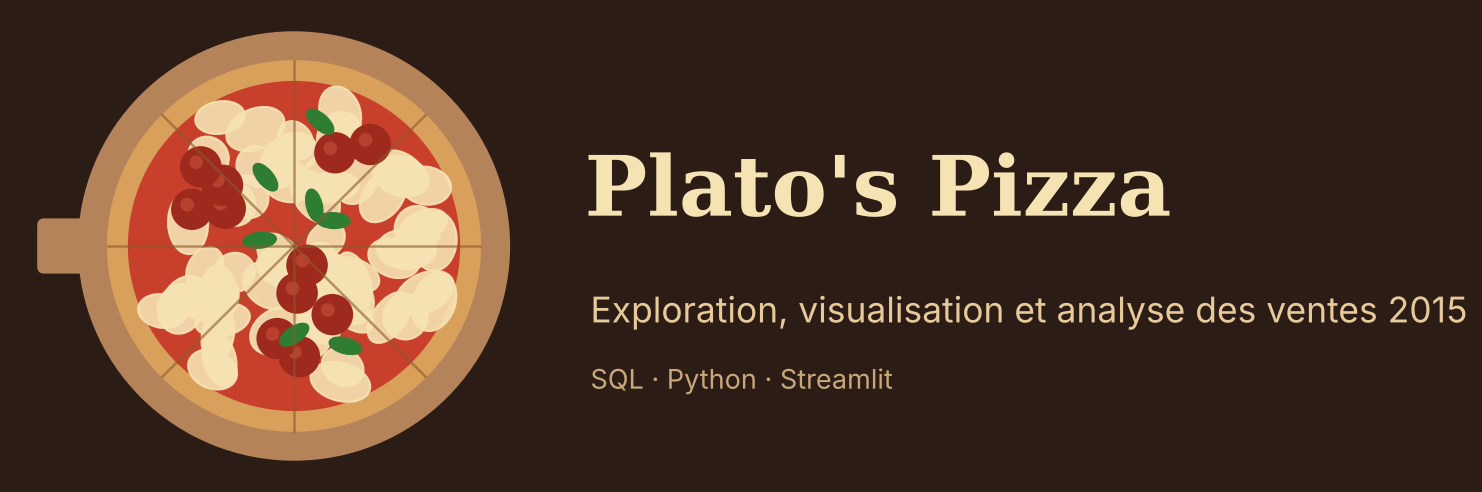

# Plato's Pizza : exploration, visualisation et analyse des ventes 2015

## Sommaire

1. [Contexte et objectifs](#contexte)
2. [Chargement des données](#chargement)
3. [Exploration préparatoire](#exploration)
    - 3.1 [Aperçu, dimensions et types](#apercu)
    - 3.2 [Valeurs manquantes et doublons](#manquants)
    - 3.3 [Clés et intégrité référentielle](#integrite)
    - 3.4 [Cohérence des valeurs](#coherence)
    - 3.5 [Couverture temporelle](#couverture)
    - 3.6 [Bilan de qualité](#bilan-qualite)
4. [Préparation de la table d'analyse](#preparation)
5. [Analyse et visualisations](#analyse)
    - 5.1 [Indicateurs clés](#kpi)
    - 5.2 [Évolution mensuelle](#mensuel)
    - 5.3 [Activité par heure](#heures)
    - 5.4 [Activité par jour de la semaine](#jours)
    - 5.5 [Zones creuses : jour × heure](#heatmap)
    - 5.6 [Classement des pizzas](#pizzas)
    - 5.7 [Catégories](#categories)
    - 5.8 [Tailles](#tailles)
    - 5.9 [Ingrédients](#ingredients)
    - 5.10 [Taille des commandes](#panier)
6. [Contrôle croisé avec la base SQL](#sql)
7. [Synthèse : constats, limites et recommandations](#synthese)


<a id="contexte"></a>
## 1. Contexte et objectifs

Plato's Pizza souhaite mieux comprendre son activité de 2015 pour appuyer ses décisions : **quand renforcer l'équipe, quelles pizzas garder à la carte, comment augmenter le panier moyen**.

Ce notebook :
- contrôle la qualité des 4 fichiers CSV avant leur chargement dans la base SQL ;
- explore et visualise les ventes avec pandas et matplotlib ;
- vérifie que les résultats Python sont identiques à ceux des requêtes SQL (`analyse.sql`).

| Fichier | Contenu |
|---|---|
| `orders.csv` | une ligne par commande : identifiant, date, heure |
| `order_details.csv` | une ligne par pizza commandée : commande, pizza, quantité |
| `pizzas.csv` | une ligne par pizza vendable : type, taille, prix |
| `pizza_types.csv` | une ligne par recette : nom, catégorie, ingrédients |


<a id="chargement"></a>
## 2. Chargement des données

In [1]:
from pathlib import Path
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# Dossier qui contient les 4 CSV (à adapter si besoin)
DATA_DIR = Path(".")

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)

orders        = pd.read_csv(DATA_DIR / "orders.csv")
order_details = pd.read_csv(DATA_DIR / "order_details.csv")
pizzas        = pd.read_csv(DATA_DIR / "pizzas.csv")
# pizza_types.csv est encodé en Windows-1252 (ingrédient « ‘Nduja »)
pizza_types   = pd.read_csv(DATA_DIR / "pizza_types.csv", encoding="cp1252")

tables = {"orders": orders, "order_details": order_details,
          "pizzas": pizzas, "pizza_types": pizza_types}
print("Fichiers chargés :", ", ".join(tables))

Fichiers chargés : orders, order_details, pizzas, pizza_types


In [2]:
# Charte graphique commune à tous les graphiques
BLEU, ORANGE, AQUA, JAUNE = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GRIS_TEXTE, GRIS_AXE, FOND = "#52514e", "#c3c2b7", "#fcfcfb"
COULEURS_CATEGORIES = {"Classic": BLEU, "Supreme": ORANGE, "Chicken": AQUA, "Veggie": JAUNE}

plt.rcParams.update({
    "figure.facecolor": FOND, "axes.facecolor": FOND, "savefig.facecolor": FOND,
    "figure.figsize": (10, 4.5), "figure.dpi": 110,
    "axes.edgecolor": GRIS_AXE, "axes.labelcolor": GRIS_TEXTE,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8,
    "xtick.color": GRIS_TEXTE, "ytick.color": GRIS_TEXTE,
    "font.size": 10,
})

def euros(x, pos=None):
    """Formate un axe en euros : 12 500 €"""
    return f"{x:,.0f} €".replace(",", " ")

<a id="exploration"></a>
## 3. Exploration préparatoire

<a id="apercu"></a>
### 3.1 Aperçu, dimensions et types

In [3]:
for nom, df in tables.items():
    print(f"{nom:<14} {df.shape[0]:>6} lignes × {df.shape[1]} colonnes")

orders          21350 lignes × 3 colonnes
order_details   48620 lignes × 4 colonnes
pizzas             96 lignes × 4 colonnes
pizza_types        32 lignes × 4 colonnes


In [4]:
for nom, df in tables.items():
    print(f"\n=== {nom} ===")
    display(df.head(3))
    print(df.dtypes.to_string())


=== orders ===


,order_id,date,time
0,1,2015-01-01,11:38:36
1,2,2015-01-01,11:57:40
2,3,2015-01-01,12:12:28


order_id    int64
date          str
time          str

=== order_details ===


,order_details_id,order_id,pizza_id,quantity
0,1,1,hawaiian_m,1
1,2,2,classic_dlx_m,1
2,3,2,five_cheese_l,1


order_details_id    int64
order_id            int64
pizza_id              str
quantity            int64

=== pizzas ===


,pizza_id,pizza_type_id,size,price
0,bbq_ckn_s,bbq_ckn,S,12.75
1,bbq_ckn_m,bbq_ckn,M,16.75
2,bbq_ckn_l,bbq_ckn,L,20.75


pizza_id             str
pizza_type_id        str
size                 str
price            float64

=== pizza_types ===


,pizza_type_id,name,category,ingredients
0,bbq_ckn,The Barbecue Chicken Pizza,Chicken,"Barbecued Chicken, Red Peppers, Green Peppers,..."
1,cali_ckn,The California Chicken Pizza,Chicken,"Chicken, Artichoke, Spinach, Garlic, Jalapeno ..."
2,ckn_alfredo,The Chicken Alfredo Pizza,Chicken,"Chicken, Red Onions, Red Peppers, Mushrooms, A..."


pizza_type_id    str
name             str
category         str
ingredients      str


**Constat :** `date` et `time` sont lues comme du texte. Il faudra les convertir pour analyser par mois, jour ou heure. `price` est un nombre décimal et `quantity` un entier : les calculs de chiffre d'affaires sont directement possibles.

<a id="manquants"></a>
### 3.2 Valeurs manquantes et doublons

In [5]:
qualite = pd.DataFrame({
    nom: {"valeurs manquantes": int(df.isna().sum().sum()),
          "lignes en double": int(df.duplicated().sum())}
    for nom, df in tables.items()
}).T
qualite

,valeurs manquantes,lignes en double
orders,0,0
order_details,0,0
pizzas,0,0
pizza_types,0,0


In [6]:
# Une même pizza apparaît-elle deux fois dans la même commande ?
doublons_commande = order_details.duplicated(["order_id", "pizza_id"]).sum()
print("Couples (commande, pizza) en double :", doublons_commande)

Couples (commande, pizza) en double : 0


**Constat :** aucune valeur manquante ni ligne dupliquée. Une pizza n'apparaît qu'une fois par commande : si un client en prend deux identiques, c'est la colonne `quantity` qui vaut 2.

<a id="integrite"></a>
### 3.3 Clés et intégrité référentielle

In [7]:
# Les identifiants sont-ils uniques ? Ils deviendront les clés primaires.
cles = {"orders": "order_id", "order_details": "order_details_id",
        "pizzas": "pizza_id", "pizza_types": "pizza_type_id"}
for nom, cle in cles.items():
    print(f"{nom:<14} {cle:<17} unique : {tables[nom][cle].is_unique}")

orders         order_id          unique : True
order_details  order_details_id  unique : True
pizzas         pizza_id          unique : True
pizza_types    pizza_type_id     unique : True


In [8]:
# Chaque référence pointe-t-elle vers une ligne existante ? Ce seront les clés étrangères.
controles = {
    "order_details.order_id -> orders":     set(order_details.order_id) - set(orders.order_id),
    "order_details.pizza_id -> pizzas":     set(order_details.pizza_id) - set(pizzas.pizza_id),
    "pizzas.pizza_type_id -> pizza_types":  set(pizzas.pizza_type_id) - set(pizza_types.pizza_type_id),
}
for lien, orphelins in controles.items():
    print(f"{lien:<38} références orphelines : {len(orphelins)}")

print("Commandes sans aucune ligne :", len(set(orders.order_id) - set(order_details.order_id)))
print("Pizzas de la carte jamais vendues :", sorted(set(pizzas.pizza_id) - set(order_details.pizza_id)))

order_details.order_id -> orders       références orphelines : 0
order_details.pizza_id -> pizzas       références orphelines : 0
pizzas.pizza_type_id -> pizza_types    références orphelines : 0
Commandes sans aucune ligne : 0
Pizzas de la carte jamais vendues : ['big_meat_l', 'big_meat_m', 'five_cheese_m', 'five_cheese_s', 'four_cheese_s']


In [9]:
# Pourquoi pizza_type_id ne peut pas être une clé primaire de pizzas
pizzas.groupby("pizza_type_id").size().value_counts().rename("nb de recettes").to_frame("nb de recettes").rename_axis("tailles proposées")

,nb de recettes
tailles proposées,
3,30
1,1
5,1


**Constat :** les 4 identifiants sont uniques et toutes les références sont valides. Le modèle relationnel peut donc s'appuyer sur ces clés sans nettoyage. Une même recette existe en plusieurs tailles : c'est `pizza_id` (recette × taille) qui identifie un produit vendu.

<a id="coherence"></a>
### 3.4 Cohérence des valeurs

In [10]:
display(order_details["quantity"].describe().to_frame().T)
display(pizzas["price"].describe().to_frame().T)
print("Tailles :", sorted(pizzas["size"].unique()))
print("Catégories :", sorted(pizza_types["category"].unique()))

,count,mean,std,min,25%,50%,75%,max
quantity,48620.0,1.019622,0.143077,1.0,1.0,1.0,1.0,4.0


,count,mean,std,min,25%,50%,75%,max
price,96.0,16.440625,4.090266,9.75,12.5,16.25,20.25,35.95


Tailles : ['L', 'M', 'S', 'XL', 'XXL']
Catégories : ['Chicken', 'Classic', 'Supreme', 'Veggie']


In [11]:
# Quelles recettes sont proposées en XL ou XXL ?
pizzas.pivot_table(index="pizza_type_id", columns="size", values="price", aggfunc="first") \
      .reindex(columns=["S", "M", "L", "XL", "XXL"]).dropna(subset=["XL"])

size,S,M,L,XL,XXL
pizza_type_id,,,,,
the_greek,12.0,16.0,20.5,25.5,35.95


In [12]:
# Encodage : le seul caractère spécial du jeu doit s'afficher correctement
pizza_types.loc[pizza_types.pizza_type_id == "calabrese", ["name", "ingredients"]]

,name,ingredients
15,The Calabrese Pizza,"‘Nduja Salami, Pancetta, Tomatoes, Red Onions,..."


**Constat :** quantités entre 1 et 4, prix entre 9,75 € et 35,95 €, 5 tailles et 4 catégories, sans valeur aberrante. Point important pour l'analyse : **seule The Greek Pizza existe en XL et XXL**. Une faible part de ces tailles ne signifie donc pas un désintérêt des clients.

<a id="couverture"></a>
### 3.5 Couverture temporelle

In [13]:
dates = pd.to_datetime(orders["date"])
heures = pd.to_datetime(orders["time"], format="%H:%M:%S")
print("Période :", dates.min().date(), "->", dates.max().date())
print("Plage horaire :", heures.min().time(), "->", heures.max().time())

calendrier = pd.date_range("2015-01-01", "2015-12-31")
jours_sans_commande = calendrier.difference(dates.unique())
print(f"Jours avec des commandes : {dates.nunique()} sur {len(calendrier)}")
pd.DataFrame({"jour sans commande": jours_sans_commande.date,
              "jour de la semaine": jours_sans_commande.day_name()})

Période : 2015-01-01 -> 2015-12-31
Plage horaire : 09:52:21 -> 23:05:52
Jours avec des commandes : 358 sur 365


,jour sans commande,jour de la semaine
0,2015-09-24,Thursday
1,2015-09-25,Friday
2,2015-10-05,Monday
3,2015-10-12,Monday
4,2015-10-19,Monday
5,2015-10-26,Monday
6,2015-12-25,Friday


**Constat :** l'année 2015 est couverte, de 9 h 52 à 23 h 05. Il manque **7 jours**, dont Noël et quatre lundis consécutifs en octobre (fermetures probables). Pour comparer les jours de la semaine, il faut donc raisonner en **moyenne par jour ouvert**, et non en totaux.

<a id="bilan-qualite"></a>
### 3.6 Bilan de qualité

| Contrôle | Résultat | Conséquence |
|---|---|---|
| Valeurs manquantes, doublons | aucun | pas de nettoyage nécessaire |
| Unicité des identifiants | OK pour les 4 tables | clés primaires possibles |
| Intégrité des références | aucune référence orpheline | clés étrangères possibles |
| Encodage | Windows-1252 pour `pizza_types.csv` | à préciser lors de l'import SQL |
| Types | dates et heures en texte | conversion nécessaire |
| Couverture | 358 jours sur 365 | moyennes par jour ouvert |
| Offre | XL et XXL : une seule recette | à garder en tête pour l'analyse des tailles |


<a id="preparation"></a>
## 4. Préparation de la table d'analyse

On reproduit en pandas le modèle en étoile de la base : chaque ligne de vente est enrichie avec la description de sa pizza et le moment de sa commande.

In [14]:
ventes = (order_details
          .merge(orders, on="order_id", how="left")
          .merge(pizzas, on="pizza_id", how="left")
          .merge(pizza_types, on="pizza_type_id", how="left"))

ventes["date"] = pd.to_datetime(ventes["date"])
ventes["heure"] = pd.to_datetime(ventes["time"], format="%H:%M:%S").dt.hour
ventes["mois"] = ventes["date"].dt.to_period("M")
ventes["jour_num"] = ventes["date"].dt.dayofweek          # 0 = lundi
JOURS = ["Lundi", "Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi", "Dimanche"]
ventes["jour"] = pd.Categorical(ventes["jour_num"].map(dict(enumerate(JOURS))), categories=JOURS, ordered=True)
ventes["ca"] = ventes["quantity"] * ventes["price"]

assert len(ventes) == len(order_details), "la jointure ne doit perdre ni dupliquer aucune ligne"
print(ventes.shape)
ventes.head(3)

(48620, 17)


,order_details_id,order_id,pizza_id,quantity,date,time,pizza_type_id,size,price,name,category,ingredients,heure,mois,jour_num,jour,ca
0,1,1,hawaiian_m,1,2015-01-01,11:38:36,hawaiian,M,13.25,The Hawaiian Pizza,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese",11,2015-01,3,Jeudi,13.25
1,2,2,classic_dlx_m,1,2015-01-01,11:57:40,classic_dlx,M,16.00,The Classic Deluxe Pizza,Classic,"Pepperoni, Mushrooms, Red Onions, Red Peppers,...",11,2015-01,3,Jeudi,16.00
2,3,2,five_cheese_l,1,2015-01-01,11:57:40,five_cheese,L,18.50,The Five Cheese Pizza,Veggie,"Mozzarella Cheese, Provolone Cheese, Smoked Go...",11,2015-01,3,Jeudi,18.50


<a id="analyse"></a>
## 5. Analyse et visualisations

<a id="kpi"></a>
### 5.1 Indicateurs clés

In [15]:
ca_total      = ventes["ca"].sum()
nb_commandes  = ventes["order_id"].nunique()
pizzas_vendues = ventes["quantity"].sum()

kpi = pd.Series({
    "Chiffre d'affaires (€)": round(ca_total, 2),
    "Commandes": nb_commandes,
    "Pizzas vendues": pizzas_vendues,
    "Panier moyen (€)": round(ca_total / nb_commandes, 2),
    "Pizzas par commande": round(pizzas_vendues / nb_commandes, 2),
    "Commandes par jour ouvert": round(nb_commandes / ventes["date"].nunique(), 1),
}, name="2015")
kpi.to_frame()

,2015
Chiffre d'affaires (€),817860.05
Commandes,21350.00
Pizzas vendues,49574.00
Panier moyen (€),38.31
Pizzas par commande,2.32
Commandes par jour ouvert,59.60


<a id="mensuel"></a>
### 5.2 Évolution mensuelle

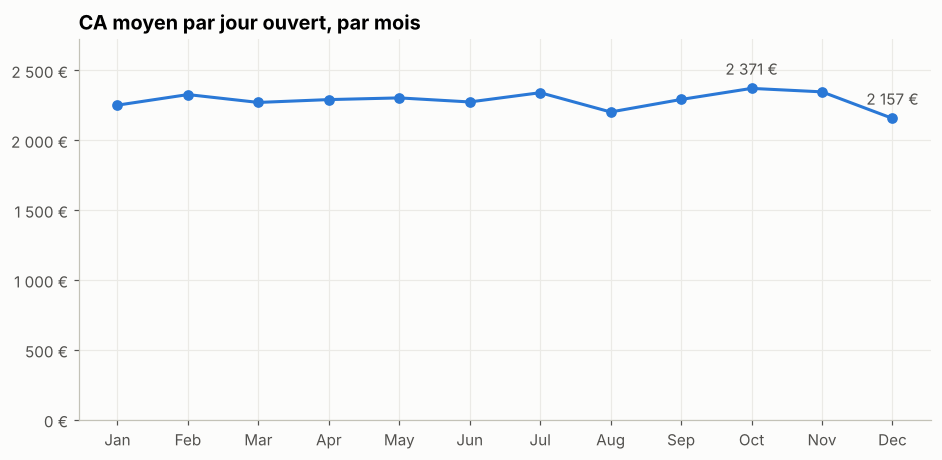

,ca,commandes,ca_par_jour
mois,,,
2015-01,69793.30,1845,2251.40
2015-02,65159.60,1685,2327.13
2015-03,70397.10,1840,2270.87
2015-04,68736.80,1799,2291.23
2015-05,71402.75,1853,2303.31
2015-06,68230.20,1773,2274.34
2015-07,72557.90,1935,2340.58
2015-08,68278.25,1841,2202.52
2015-09,64180.05,1661,2292.14


In [16]:
par_mois = ventes.groupby("mois").agg(ca=("ca", "sum"), commandes=("order_id", "nunique"))
jours_ouverts = ventes.groupby("mois")["date"].nunique()
par_mois["ca_par_jour"] = par_mois["ca"] / jours_ouverts

fig, ax = plt.subplots()
x = par_mois.index.strftime("%b")
ax.plot(x, par_mois["ca_par_jour"], color=BLEU, linewidth=2, marker="o", markersize=6)
ax.set_title("CA moyen par jour ouvert, par mois")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(euros))
ax.set_ylim(0, par_mois["ca_par_jour"].max() * 1.15)
for i in [par_mois["ca_par_jour"].values.argmax(), par_mois["ca_par_jour"].values.argmin()]:
    ax.annotate(euros(par_mois["ca_par_jour"].iloc[i]), (i, par_mois["ca_par_jour"].iloc[i]),
                textcoords="offset points", xytext=(0, 9), ha="center", color=GRIS_TEXTE)
plt.show()
par_mois.round(2)

**Lecture :** l'activité est **stable toute l'année**, sans forte saisonnalité. On raisonne en CA par jour ouvert pour ne pas pénaliser les mois avec des jours de fermeture, comme octobre.

<a id="heures"></a>
### 5.3 Activité par heure

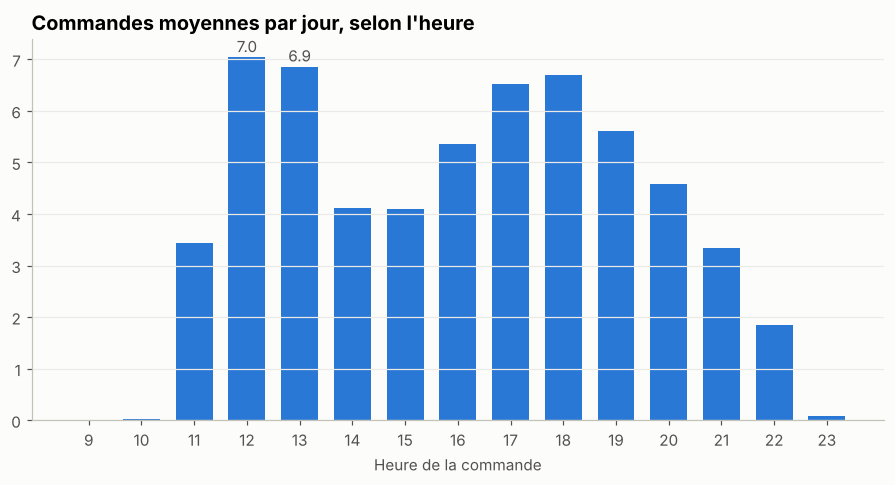

,commandes,ca,commandes_par_jour,panier_moyen
heure,,,,
9,1,83.00,0.00,83.00
10,8,303.65,0.02,37.96
11,1231,44935.80,3.44,36.50
12,2520,111877.90,7.04,44.40
13,2455,106065.70,6.86,43.20
14,1472,59201.40,4.11,40.22
15,1468,52992.30,4.10,36.10
16,1920,70055.40,5.36,36.49
17,2336,86237.45,6.53,36.92


In [17]:
par_heure = ventes.groupby("heure").agg(commandes=("order_id", "nunique"), ca=("ca", "sum"))
par_heure["commandes_par_jour"] = par_heure["commandes"] / ventes["date"].nunique()
par_heure["panier_moyen"] = par_heure["ca"] / par_heure["commandes"]

fig, ax = plt.subplots()
ax.bar(par_heure.index, par_heure["commandes_par_jour"], color=BLEU, width=0.7)
ax.set_title("Commandes moyennes par jour, selon l'heure")
ax.set_xlabel("Heure de la commande")
ax.set_xticks(par_heure.index)
ax.grid(axis="x", visible=False)
top = par_heure["commandes_par_jour"].nlargest(2)
for h, v in top.items():
    ax.text(h, v + 0.1, f"{v:.1f}", ha="center", color=GRIS_TEXTE)
plt.show()
par_heure.round(2)

**Lecture :** deux pics se dégagent, **le déjeuner (12 h-13 h)** et **le dîner (17 h-19 h)**. Avant 11 h et après 22 h, l'activité est quasi nulle. Le panier moyen est aussi plus élevé au déjeuner : il s'agit probablement de commandes de groupe ou de bureau.

<a id="jours"></a>
### 5.4 Activité par jour de la semaine

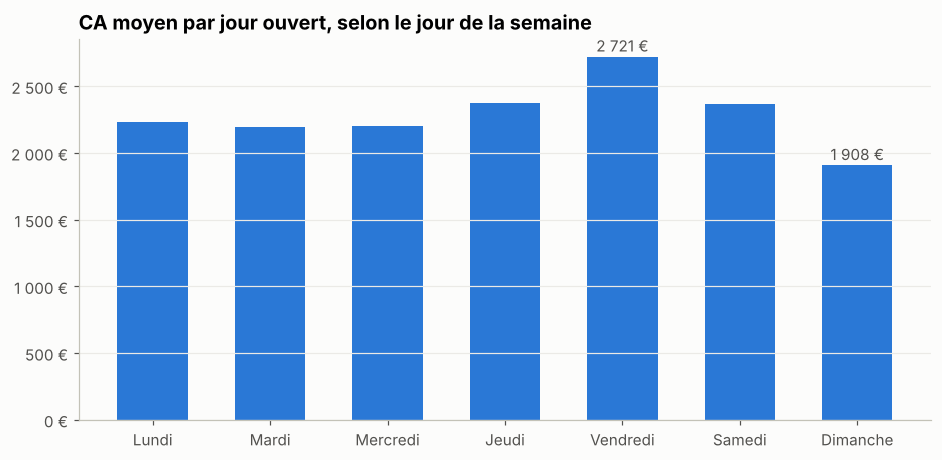

,ca,commandes,nb_jours,ca_par_jour,panier_moyen
jour,,,,,
Lundi,107329.55,2794,48,2236.03,38.41
Mardi,114133.80,2973,52,2194.88,38.39
Mercredi,114408.40,3024,52,2200.16,37.83
Jeudi,123528.50,3239,52,2375.55,38.14
Vendredi,136073.90,3538,50,2721.48,38.46
Samedi,123182.40,3158,52,2368.89,39.01
Dimanche,99203.50,2624,52,1907.76,37.81


In [18]:
par_jour = ventes.groupby("jour", observed=True).agg(
    ca=("ca", "sum"), commandes=("order_id", "nunique"), nb_jours=("date", "nunique"))
par_jour["ca_par_jour"] = par_jour["ca"] / par_jour["nb_jours"]
par_jour["panier_moyen"] = par_jour["ca"] / par_jour["commandes"]

fig, ax = plt.subplots()
ax.bar(par_jour.index.astype(str), par_jour["ca_par_jour"], color=BLEU, width=0.6)
ax.set_title("CA moyen par jour ouvert, selon le jour de la semaine")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(euros))
ax.grid(axis="x", visible=False)
for j, v in par_jour["ca_par_jour"].items():
    if v in (par_jour["ca_par_jour"].max(), par_jour["ca_par_jour"].min()):
        ax.text(str(j), v + 40, euros(v), ha="center", color=GRIS_TEXTE)
plt.show()
par_jour.round(2)

**Lecture :** **le vendredi est le jour le plus fort**, suivi du jeudi et du samedi. Le **dimanche est le plus faible**. Le panier moyen varie peu d'un jour à l'autre : l'écart vient du nombre de commandes, pas de leur montant.

<a id="heatmap"></a>
### 5.5 Zones creuses : jour × heure

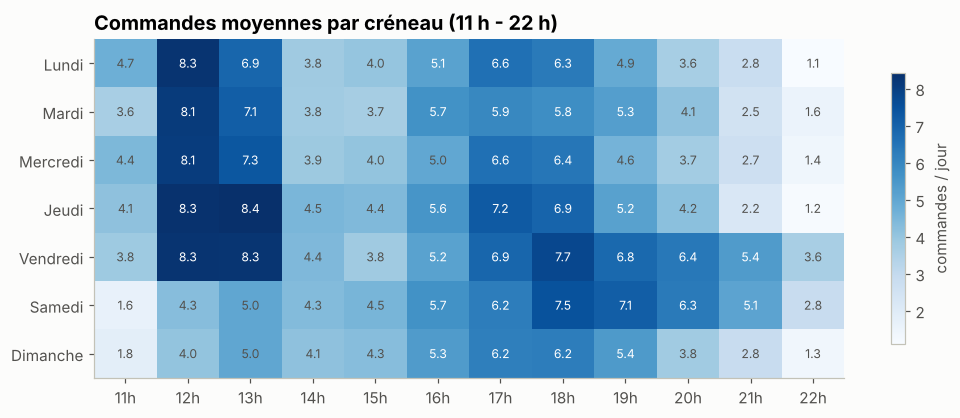

In [19]:
nb_jours_type = ventes.groupby("jour", observed=True)["date"].nunique()
carte = (ventes.groupby(["jour", "heure"], observed=True)["order_id"].nunique()
               .unstack(fill_value=0)
               .div(nb_jours_type, axis=0)
               .loc[:, 11:22])

fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(carte.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(carte.shape[1]), [f"{h}h" for h in carte.columns])
ax.set_yticks(range(carte.shape[0]), carte.index.astype(str))
ax.grid(False)
for (i, j), v in np.ndenumerate(carte.values):
    ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8,
            color="white" if v > carte.values.max() * 0.6 else GRIS_TEXTE)
ax.set_title("Commandes moyennes par créneau (11 h - 22 h)")
fig.colorbar(im, ax=ax, shrink=0.8, label="commandes / jour")
plt.show()

**Lecture :** les cases les plus foncées sont le **déjeuner en semaine** et le **dîner du vendredi et du samedi**. Les **zones creuses** sont l'après-midi (14 h-15 h), la fin de soirée (après 21 h) en semaine et le dimanche, et 11 h le week-end. Ces créneaux se prêtent à des offres ciblées ou à un allègement du personnel.

<a id="pizzas"></a>
### 5.6 Classement des pizzas

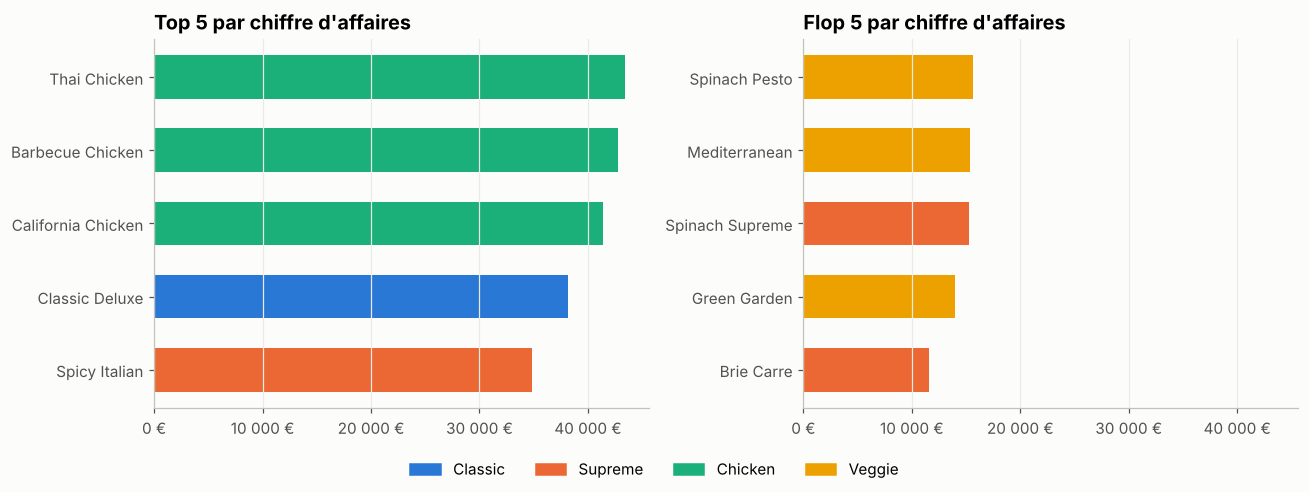

,name,category,quantite,ca,rang_ca,rang_quantite
30,The Thai Chicken Pizza,Chicken,2371,43434.25,1,5
0,The Barbecue Chicken Pizza,Chicken,2432,42768.00,2,2
4,The California Chicken Pizza,Chicken,2370,41409.50,3,6
7,The Classic Deluxe Pizza,Classic,2453,38180.50,4,1
26,The Spicy Italian Pizza,Supreme,1924,34831.25,5,8
25,The Southwest Chicken Pizza,Chicken,1917,34705.75,6,9
14,The Italian Supreme Pizza,Supreme,1884,33476.75,7,12
12,The Hawaiian Pizza,Classic,2422,32273.25,8,3
9,The Four Cheese Pizza,Veggie,1902,32265.70,9,11
23,The Sicilian Pizza,Supreme,1938,30940.50,10,7


In [20]:
par_pizza = (ventes.groupby(["name", "category"])
                   .agg(quantite=("quantity", "sum"), ca=("ca", "sum"))
                   .reset_index()
                   .sort_values("ca", ascending=False))
par_pizza["rang_ca"] = par_pizza["ca"].rank(ascending=False).astype(int)
par_pizza["rang_quantite"] = par_pizza["quantite"].rank(ascending=False, method="min").astype(int)

def barres_horizontales(df, titre, ax):
    couleurs = df["category"].map(COULEURS_CATEGORIES)
    ax.barh(df["name"].str.replace("The ", "").str.replace(" Pizza", ""), df["ca"], color=couleurs, height=0.6)
    ax.invert_yaxis()
    ax.set_title(titre)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(euros))
    ax.grid(axis="y", visible=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
barres_horizontales(par_pizza.head(5), "Top 5 par chiffre d'affaires", axes[0])
barres_horizontales(par_pizza.tail(5), "Flop 5 par chiffre d'affaires", axes[1])
poignees = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COULEURS_CATEGORIES.values()]
fig.legend(poignees, COULEURS_CATEGORIES.keys(), loc="lower center", ncol=4, frameon=False)
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()
par_pizza.round(2)

**Lecture :** les pizzas au **poulet** dominent le chiffre d'affaires (The Thai Chicken est n°1). The Classic Deluxe est la plus vendue en quantité, mais seulement 4ᵉ en CA, car son prix est plus bas. En bas du classement, **The Brie Carre** rapporte près de 4 fois moins que la n°1. C'est la première candidate à une révision de la carte.

<a id="categories"></a>
### 5.7 Catégories

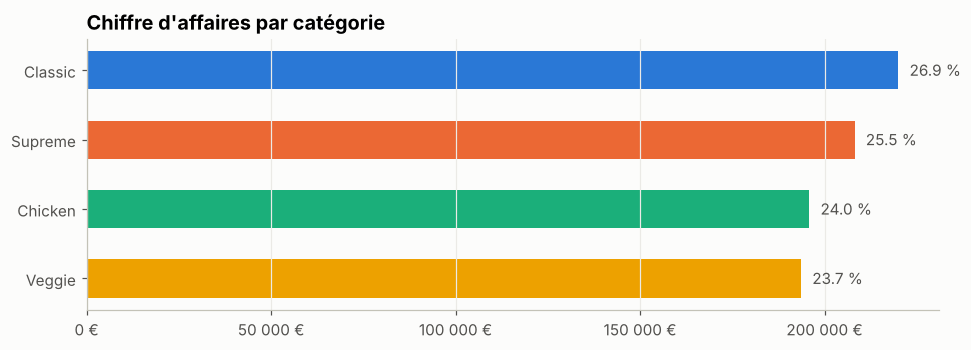

,ca,quantite,part_ca_%,prix_moyen
category,,,,
Veggie,193690.45,11649,23.68,16.63
Chicken,195919.50,11050,23.96,17.73
Supreme,208197.00,11987,25.46,17.37
Classic,220053.10,14888,26.91,14.78


In [21]:
par_cat = ventes.groupby("category").agg(ca=("ca", "sum"), quantite=("quantity", "sum")).sort_values("ca")
par_cat["part_ca_%"] = 100 * par_cat["ca"] / par_cat["ca"].sum()
par_cat["prix_moyen"] = par_cat["ca"] / par_cat["quantite"]

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.barh(par_cat.index, par_cat["ca"], color=[COULEURS_CATEGORIES[c] for c in par_cat.index], height=0.55)
for cat, row in par_cat.iterrows():
    ax.text(row["ca"] + 3000, cat, f"{row['part_ca_%']:.1f} %", va="center", color=GRIS_TEXTE)
ax.set_title("Chiffre d'affaires par catégorie")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(euros))
ax.grid(axis="y", visible=False)
plt.show()
par_cat.round(2)

**Lecture :** les 4 catégories pèsent chacune **entre 23,7 et 26,9 % du CA** : la carte est équilibrée. Classic vend le plus d'unités, mais Chicken a le prix moyen le plus élevé.

<a id="tailles"></a>
### 5.8 Tailles

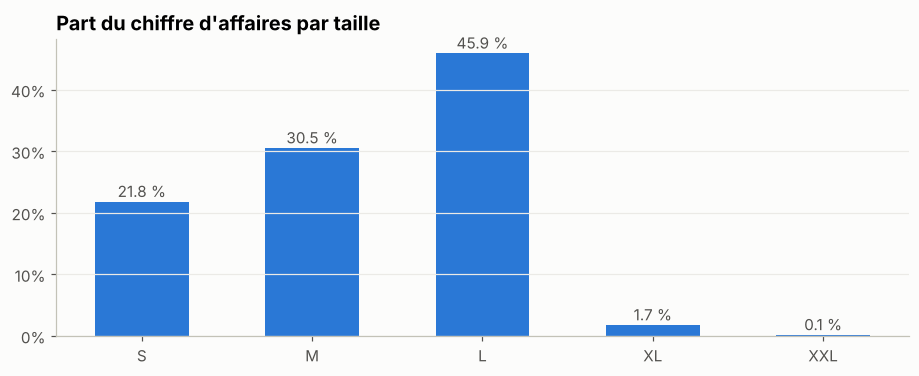

,quantite,ca,part_ca_%,prix_moyen
size,,,,
S,14403,178076.50,21.77,12.36
M,15635,249382.25,30.49,15.95
L,18956,375318.70,45.89,19.80
XL,552,14076.00,1.72,25.50
XXL,28,1006.60,0.12,35.95


In [22]:
ORDRE_TAILLES = ["S", "M", "L", "XL", "XXL"]
par_taille = ventes.groupby("size").agg(quantite=("quantity", "sum"), ca=("ca", "sum")).reindex(ORDRE_TAILLES)
par_taille["part_ca_%"] = 100 * par_taille["ca"] / par_taille["ca"].sum()
par_taille["prix_moyen"] = par_taille["ca"] / par_taille["quantite"]

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(par_taille.index, par_taille["part_ca_%"], color=BLEU, width=0.55)
for t, v in par_taille["part_ca_%"].items():
    ax.text(t, v + 0.8, f"{v:.1f} %", ha="center", color=GRIS_TEXTE)
ax.set_title("Part du chiffre d'affaires par taille")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.grid(axis="x", visible=False)
plt.show()
par_taille.round(2)

**Lecture :** la **taille L** génère près de la moitié du CA. XL et XXL pèsent moins de 2 %, mais ne sont proposées que pour une seule recette (voir 3.4). Avant de les supprimer, on peut tester une offre XL sur les pizzas les plus vendues.

<a id="ingredients"></a>
### 5.9 Ingrédients

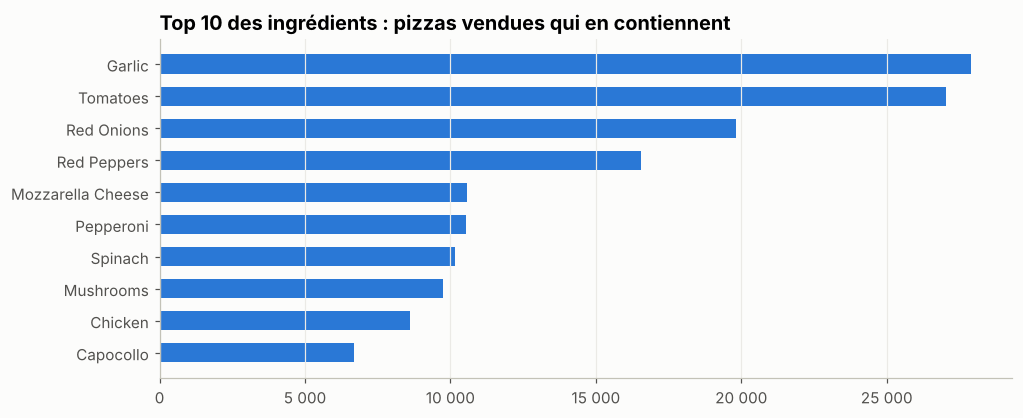

Ingrédients distincts : 65


In [23]:
# La colonne ingredients est une liste "a, b, c" : on l'éclate en une ligne par ingrédient
ingredients = (ventes[["quantity", "ingredients"]]
               .assign(ingredient=ventes["ingredients"].str.split(", "))
               .explode("ingredient"))
top_ingr = ingredients.groupby("ingredient")["quantity"].sum().nlargest(10).sort_values()

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(top_ingr.index, top_ingr.values, color=BLEU, height=0.6)
ax.set_title("Top 10 des ingrédients : pizzas vendues qui en contiennent")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f"{x:,.0f}".replace(",", " ")))
ax.grid(axis="y", visible=False)
plt.show()
print("Ingrédients distincts :", ingredients["ingredient"].nunique())

**Lecture :** l'**ail** et les **tomates** entrent dans plus de la moitié des pizzas vendues. Ce sont les ingrédients à sécuriser en priorité dans les achats. Limite : on connaît la présence d'un ingrédient, pas sa quantité par pizza.

<a id="panier"></a>
### 5.10 Taille des commandes

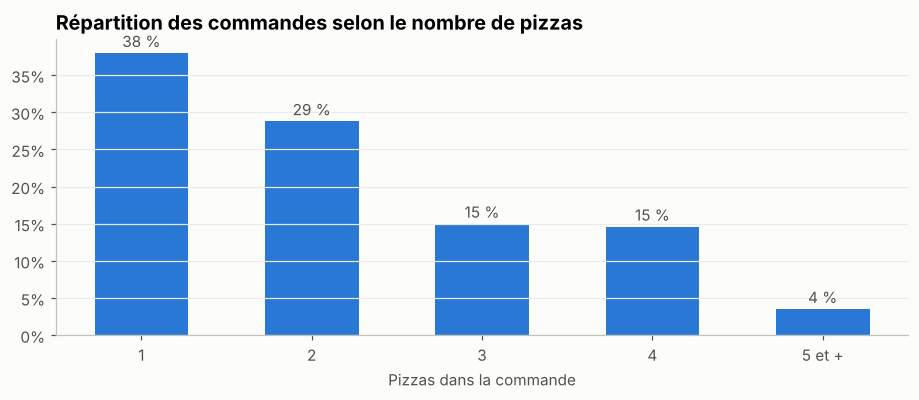

,commandes,montant_moyen,part_%
1,8111,16.52,37.99
2,6152,32.99,28.81
3,3207,49.38,15.02
4,3122,66.00,14.62
5 et +,758,153.72,3.55


In [24]:
par_commande = ventes.groupby("order_id").agg(nb_pizzas=("quantity", "sum"), montant=("ca", "sum"))
repartition = par_commande.groupby(par_commande["nb_pizzas"].clip(upper=5)).agg(
    commandes=("montant", "size"), montant_moyen=("montant", "mean"))
repartition["part_%"] = 100 * repartition["commandes"] / repartition["commandes"].sum()
repartition.index = [str(i) if i < 5 else "5 et +" for i in repartition.index]

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(repartition.index, repartition["part_%"], color=BLEU, width=0.55)
for k, v in repartition["part_%"].items():
    ax.text(k, v + 0.8, f"{v:.0f} %", ha="center", color=GRIS_TEXTE)
ax.set_title("Répartition des commandes selon le nombre de pizzas")
ax.set_xlabel("Pizzas dans la commande")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.grid(axis="x", visible=False)
plt.show()
repartition.round(2)

**Lecture :** **38 % des commandes ne contiennent qu'une seule pizza**, pour un montant moyen d'environ 16,50 €. C'est le principal levier pour augmenter le panier moyen : une offre « 2ᵉ pizza » ou un menu avec boisson et dessert.

<a id="sql"></a>
## 6. Contrôle croisé avec la base SQL

Les chiffres calculés en pandas doivent être **identiques** à ceux de la base SQL. On interroge `plato_pizza.db` (modèle en étoile créé par `creation_base.sql`). Si le fichier est absent, la base est reconstruite en mémoire à partir des CSV et du script.

In [25]:
DB_PATH = DATA_DIR / "plato_pizza.db"
SCRIPT = DATA_DIR / "creation_base.sql"

if DB_PATH.exists():
    con = sqlite3.connect(DB_PATH)
    print("Connexion à", DB_PATH)
else:
    con = sqlite3.connect(":memory:")
    for nom, df in tables.items():
        df.to_sql(nom, con, index=False)
    script = SCRIPT.read_text(encoding="utf-8").split("-- 8.")[0]   # sans les contrôles finaux
    con.executescript(script)
    print("Base reconstruite en mémoire à partir de", SCRIPT)

Base reconstruite en mémoire à partir de creation_base.sql


In [26]:
requete_q1 = """
SELECT ROUND(SUM(fv.quantity * dp.price), 2)                               AS chiffre_affaires,
       COUNT(DISTINCT fv.order_id)                                         AS nb_commandes,
       SUM(fv.quantity)                                                    AS pizzas_vendues,
       ROUND(SUM(fv.quantity * dp.price) / COUNT(DISTINCT fv.order_id), 2) AS panier_moyen
FROM faits_ventes fv
JOIN dim_pizza dp    ON dp.pizza_id = fv.pizza_id
JOIN dim_commande dc ON dc.order_id = fv.order_id
WHERE dc.order_date BETWEEN :date_debut AND :date_fin
"""
sql = pd.read_sql(requete_q1, con, params={"date_debut": "2015-01-01", "date_fin": "2015-12-31"})

comparaison = pd.DataFrame({
    "SQL": sql.iloc[0].values,
    "pandas": [round(ca_total, 2), nb_commandes, pizzas_vendues, round(ca_total / nb_commandes, 2)],
}, index=sql.columns)
comparaison["identique"] = np.isclose(comparaison["SQL"].astype(float), comparaison["pandas"].astype(float))
comparaison

,SQL,pandas,identique
chiffre_affaires,817860.05,817860.05,True
nb_commandes,21350.00,21350.00,True
pizzas_vendues,49574.00,49574.00,True
panier_moyen,38.31,38.31,True


**Constat :** SQL et pandas donnent exactement les mêmes résultats. La base est fiable, et l'application Streamlit pourra s'appuyer directement sur les requêtes de `analyse.sql`.

<a id="synthese"></a>
## 7. Synthèse : constats, limites et recommandations

### Constats clés
| Thème | Constat |
|---|---|
| Activité | 817 860 € de CA, 21 350 commandes, panier moyen de 38,31 €, activité stable sur l'année |
| Temps | pics au déjeuner (12 h-13 h) et au dîner (17 h-19 h) ; vendredi = jour le plus fort, dimanche = le plus faible |
| Produits | pizzas au poulet en tête du CA ; carte équilibrée entre catégories ; The Brie Carre en dernière position |
| Tailles | L = près de la moitié du CA ; XL et XXL marginales, mais proposées sur une seule recette |
| Panier | 38 % des commandes ne comptent qu'une pizza |

### Recommandations
1. **Personnel** : renforcer l'équipe au déjeuner en semaine et le vendredi soir ; alléger l'après-midi et la fin de soirée.
2. **Panier moyen** : lancer une offre « 2ᵉ pizza » ou un menu pour convertir les commandes d'une seule pizza.
3. **Carte** : revoir les recettes du bas du classement (The Brie Carre, The Green Garden) ; mettre en avant les pizzas au poulet.
4. **Tailles** : tester le format XL sur les 3 pizzas les plus vendues avant de décider de le maintenir ou de le supprimer.
5. **Créneaux creux** : proposer des promotions sur les créneaux 14 h-15 h et après 21 h (hors vendredi et samedi).

### Limites
- Une seule année de données : impossible de confirmer une saisonnalité.
- Pas de coûts : on analyse le chiffre d'affaires, pas la marge.
- Pas d'information sur les clients ni sur le canal (sur place, à emporter, livraison).
- Ingrédients sans quantités : l'analyse des achats reste indicative.
